# Tarea 2 · Deep Learning (CIT3360) — Parte 3: robustez ante degradaciones

> **Variante 80/10/10.** Copia de `../06_robustez.ipynb` que degrada el test de la partición 80/10/10 de esta carpeta (301 imágenes; huella `84ea7ae5b688`). Evalúa el modelo de `CLAVE_MODELO`, el mismo del original; si en el `05` de esta carpeta el mejor es otro, la elección es del grupo. Evalúa con NMS de IoU 0,5 (en el original, 0,7), como los demás cuadernos de esta carpeta.

Mide cuánto cae el desempeño del mejor modelo cuando las imágenes de test se degradan. Solo hace inferencia: no entrena nada.

**Ítems de la rúbrica**
- 3.1 (al menos 3 tipos o niveles de degradación): sección 3, con 3 tipos y 3 niveles por tipo.
- 3.2 (robustez del mejor modelo, con las mismas métricas): secciones 4 y 5.
- 3.3 (cómo afectan las condiciones y cuáles degradan más): sección 6, que completa el grupo.

**Requiere:** `best.pt` de `03` en `~/tarea2_runs_80_10_10/reales/` y los resultados de `05` en `resultados/comparacion/`.

**Índice:** 1 Entorno · 2 Datos · 3 Conjuntos degradados (3.1) · 4 Evaluación (3.2) · 5 Resultados (3.2) · 6 Análisis ✍️ (3.3) · 7 Exportación · Declaración de IA

Las secciones marcadas con ✍️ las completa el grupo.

## 1. Entorno y configuración

La GPU se usa solo para la inferencia de YOLO. El resto del cuaderno usa la CPU.

In [1]:
import json
import os
import random
import shutil
import zlib
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

os.environ["YOLO_VERBOSE"] = "False"   # sin barras de progreso ni un informe por cada evaluación; debe ir antes de importar ultralytics
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from PIL import Image
from ultralytics import YOLO

from comun import cargar_particiones, verificar_huella, cargar_cajas_reales, evaluar_detecciones, iou, CARPETA_RUNS, COLUMNAS_CAJA

DISPOSITIVO = 0 if torch.cuda.is_available() else "cpu"
cv2.setNumThreads(1)   # el paralelismo lo hacen los hilos de la sección 3

Todos los parámetros están aquí. Los tipos de degradación los eligió el grupo. Los niveles son una propuesta, que el grupo confirma o cambia en `DEGRADACIONES` y justifica en la sección 6.

| Tipo | Operación | Leve | Medio | Fuerte |
|---|---|---|---|---|
| Reducción de iluminación | Multiplica cada píxel por un factor | 0,6 | 0,4 | 0,2 |
| Desenfoque | Filtro gaussiano, con σ en píxeles de la imagen original | 2 | 4 | 8 |
| Ruido | Suma ruido gaussiano, con σ en niveles de 0 a 255 | 10 | 25 | 50 |

Las degradaciones se aplican a las imágenes originales. Después, YOLO las reduce a 640 px, igual que en su evaluación normal.

In [2]:
RAIZ = Path.cwd()
PRUEBA_RAPIDA = False              # True: usa solo N_IMAGENES_PRUEBA imágenes y guarda las salidas en carpetas de prueba
N_IMAGENES_PRUEBA = 40
# El modelo con mejor desempeño según la sección C de 05 (ítem 3.2)
CLAVE_MODELO = "yolo_preentrenado"
MODELO = "YOLO preentrenado"
UMBRAL_CONFIANZA = 0.25            # D8: umbral común que fijó el grupo con validación
CONFIANZA_MINIMA = 0.001           # confianza mínima de las detecciones para el mAP, igual que en 03
IOU_NMS = 0.5                      # IoU del NMS, igual que en 03
IOU_ENCONTRADA = 0.5               # IoU mínimo para contar una caja real como encontrada
LADO = 640                         # lado de entrada del modelo, igual que en 03
LOTE = 16                          # igual que en la evaluación de 03
SEMILLA = 42                       # para el ruido y para elegir imágenes
CALIDAD_JPEG = 95                  # calidad al guardar las imágenes degradadas
HILOS = 8                          # hilos para generar las imágenes
N_EJEMPLOS = 2                     # imágenes de test que se dibujan con sus detecciones
N_IMAGENES_SIGMA = 20              # imágenes de test en las que se mide el σ real del ruido
LIMITES_TAMANO = [0, 32, 64, 128, np.inf]   # grupos de tamaño de los objetos, en px de la entrada de LADO
ETIQUETAS_TAMANO = ["Menos de 32 px", "32 a 64 px", "64 a 128 px", "128 px o más"]

NIVELES = ["Leve", "Medio", "Fuerte"]
DEGRADACIONES = {                  # el valor de cada nivel, de leve a fuerte
    "iluminacion": [0.6, 0.4, 0.2],    # factor por el que se multiplica cada píxel
    "desenfoque": [2, 4, 8],           # sigma del filtro gaussiano, en píxeles de la imagen original
    "ruido": [10, 25, 50],             # desviación estándar del ruido gaussiano, en niveles de 0 a 255
}
NOMBRES_TIPO = {"iluminacion": "Reducción de iluminación", "desenfoque": "Desenfoque", "ruido": "Ruido"}

DIR_DATASET = RAIZ / "datasets" / "fjordfish"
DIR_SPLITS = RAIZ / "splits"
DIR_RUNS = CARPETA_RUNS / ("pruebas" if PRUEBA_RAPIDA else "reales") / "robustez"   # imágenes y evaluaciones, fuera de OneDrive
DIR_CONJUNTOS = DIR_RUNS / "conjuntos"
DIR_EVALUACIONES = DIR_RUNS / "evaluaciones"
DIR_RESULTADOS = (RAIZ / "pruebas" / "resultados" if PRUEBA_RAPIDA else RAIZ / "resultados") / "robustez"
DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)
DIR_COMPARACION = RAIZ / "resultados" / "comparacion"
PESOS = CARPETA_RUNS / "reales" / CLAVE_MODELO / "entrenamiento" / "weights" / "best.pt"
PREDICCIONES_TEST = RAIZ / "resultados" / CLAVE_MODELO / "predicciones_test.csv"

Estilo común de las figuras, con la misma paleta de los otros cuadernos. Cada tipo de degradación mantiene su color. `guardar` deja cada figura en `resultados/robustez/`, con una leyenda abajo cuando hace falta.

In [3]:
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#898781"
FONDO, TINTA = "#fcfcfb", "#0b0b0b"
COLORES_TIPO = dict(zip(DEGRADACIONES, [AZUL, NARANJA, AQUA]))
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "axes.titlecolor": TINTA,
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False, "figure.dpi": 100,
})
MAPA_AP = LinearSegmentedColormap.from_list("ap", ["#cde2fb", "#6da7ec", "#2a78d6", "#184f95", "#0d366b"])   # un solo tono, de claro a oscuro


def guardar(fig, nombre, con_leyenda=False):
    """Ajusta y guarda una figura; con_leyenda agrega abajo la leyenda de los tipos de degradación."""
    if con_leyenda:
        marcas = [Line2D([], [], color=COLORES_TIPO[t], lw=2, marker="o", label=NOMBRES_TIPO[t]) for t in DEGRADACIONES]
        fig.legend(handles=marcas, loc="lower center", ncol=len(marcas))
        fig.tight_layout(rect=(0, 0.08, 1, 1))
    else:
        fig.tight_layout()
    fig.savefig(DIR_RESULTADOS / nombre, dpi=150, bbox_inches="tight")
    plt.show()

## 2. Datos y verificación

Se comprueba que las particiones sean las comunes, que el modelo evaluado sea el primero de la tabla de `05` y que el umbral sea el que usó `05`. Como las degradaciones no mueven los objetos, las cajas reales son las mismas en todas las condiciones.

In [4]:
particion, huella = cargar_particiones(DIR_SPLITS)
verificar_huella(huella)
primero = pd.read_csv(DIR_COMPARACION / "mejor_modelo.csv", index_col=0).index[0]
assert primero == MODELO, f"La tabla de 05 pone primero a {primero}, pero MODELO es {MODELO}: revisar la decisión del grupo o adaptar este cuaderno"
umbral_05 = json.loads((DIR_COMPARACION / "umbral.json").read_text(encoding="utf-8"))["umbral_confianza"]
assert umbral_05 == UMBRAL_CONFIANZA, f"05 usó el umbral {umbral_05}, pero UMBRAL_CONFIANZA es {UMBRAL_CONFIANZA}"

ids = particion["test"][:N_IMAGENES_PRUEBA] if PRUEBA_RAPIDA else particion["test"]
NOMBRES = yaml.safe_load((DIR_DATASET / "fjordfish.yaml").read_text(encoding="utf-8"))["names"]
reales = cargar_cajas_reales(DIR_DATASET, "test", ids)
print(f"Modelo: {MODELO} | huella: {huella} | {len(ids)} imágenes y {len(reales)} cajas reales de test")

Modelo: YOLO preentrenado | huella: 84ea7ae5b688 | 301 imágenes y 649 cajas reales de test


## 3. Conjuntos de test degradados (ítem 3.1)

Cada condición es una copia del test con una degradación, guardada fuera de OneDrive. Una condición extra, `sin_degradar`, pasa por el mismo proceso sin modificarse: sirve de referencia, porque guardar de nuevo en JPEG también cambia un poco la imagen. El ruido usa una semilla por imagen, así que el resultado se repite siempre.

Cada condición guarda en `firma.json` los parámetros con que se generó. Si el archivo falta o no coincide, la condición se genera de nuevo.

In [5]:
def degradar(imagen, tipo, valor, semilla):
    """Devuelve la imagen degradada; sin tipo, la devuelve tal cual."""
    if tipo == "iluminacion":
        return (imagen * valor).astype(np.uint8)
    if tipo == "desenfoque":
        return cv2.GaussianBlur(imagen, (0, 0), valor)
    if tipo == "ruido":
        ruido = np.random.default_rng(semilla).normal(0, valor, imagen.shape)
        return np.clip(imagen + ruido, 0, 255).astype(np.uint8)
    return imagen


def generar_imagen(id_img, carpeta, tipo, valor):
    """Degrada una imagen de test, la guarda en JPEG y copia sus etiquetas."""
    imagen = cv2.imread(str(DIR_DATASET / "images" / "test" / f"{id_img}.jpg"))
    salida = degradar(imagen, tipo, valor, [SEMILLA, zlib.crc32(id_img.encode())])
    destino = carpeta / "images" / "test" / f"{id_img}.jpg"
    guardada = cv2.imwrite(str(destino), salida, [cv2.IMWRITE_JPEG_QUALITY, CALIDAD_JPEG])
    assert guardada, f"No se pudo guardar {destino}"
    etiquetas = DIR_DATASET / "labels" / "test" / f"{id_img}.txt"
    if etiquetas.exists():
        shutil.copy(etiquetas, carpeta / "labels" / "test" / etiquetas.name)


def firma_vigente(carpeta, firma):
    """Indica si la condición ya se generó con estos mismos parámetros."""
    archivo = carpeta / "firma.json"
    return archivo.exists() and json.loads(archivo.read_text(encoding="utf-8")) == firma


def generar_condicion(nombre, tipo, valor):
    """Crea el conjunto de una condición y su YAML; solo reutiliza las imágenes si su firma coincide."""
    carpeta = DIR_CONJUNTOS / nombre
    firma = {"tipo": tipo, "valor": valor, "semilla": SEMILLA, "calidad": CALIDAD_JPEG, "imagenes": len(ids)}
    if not firma_vigente(carpeta, firma):
        shutil.rmtree(carpeta, ignore_errors=True)   # no deben quedar imágenes de otra generación
        for subcarpeta in ("images", "labels"):
            (carpeta / subcarpeta / "test").mkdir(parents=True, exist_ok=True)
        with ThreadPoolExecutor(HILOS) as hilos:
            list(hilos.map(lambda i: generar_imagen(i, carpeta, tipo, valor), ids))
        (carpeta / "firma.json").write_text(json.dumps(firma), encoding="utf-8")   # al final: si se interrumpe, no queda firma
    config_yaml = {"path": str(carpeta), "train": "images/test", "val": "images/test", "test": "images/test", "nc": len(NOMBRES), "names": NOMBRES}
    (carpeta / "datos.yaml").write_text(yaml.safe_dump(config_yaml, allow_unicode=True), encoding="utf-8")
    n_imagenes = len(list((carpeta / "images" / "test").glob("*.jpg")))
    assert n_imagenes == len(ids), f"{nombre} tiene {n_imagenes} imágenes y se esperaban {len(ids)}"

Lista de condiciones y generación de sus imágenes. Tarda un par de minutos la primera vez.

In [6]:
CONDICIONES = {"sin_degradar": dict(tipo=None, valor=None, nivel="Sin degradar")}
for tipo, valores in DEGRADACIONES.items():
    for nivel, valor in zip(NIVELES, valores):
        CONDICIONES[f"{tipo}_{valor}"] = dict(tipo=tipo, valor=valor, nivel=nivel)

for nombre, c in CONDICIONES.items():
    generar_condicion(nombre, c["tipo"], c["valor"])
print(f"{len(CONDICIONES)} condiciones en {DIR_CONJUNTOS}")

10 condiciones en C:\Users\rslat\tarea2_runs_80_10_10\reales\robustez\conjuntos


Funciones para mostrar una imagen en todas las condiciones: una fila por tipo y una columna por nivel. Si se les pasan detecciones, también las dibujan.

In [7]:
def dibujar_condicion(ax, id_img, nombre, titulo, detecciones=None):
    """Muestra una imagen en una condición y, si se indican, sus detecciones sobre el umbral común."""
    imagen = cv2.cvtColor(cv2.imread(str(DIR_CONJUNTOS / nombre / "images" / "test" / f"{id_img}.jpg")), cv2.COLOR_BGR2RGB)
    ax.imshow(imagen)
    if detecciones is not None:
        for fila in detecciones[nombre].query("id == @id_img and confianza >= @UMBRAL_CONFIANZA").itertuples():
            ax.add_patch(plt.Rectangle((fila.x1, fila.y1), fila.x2 - fila.x1, fila.y2 - fila.y1, fill=False, ec=NARANJA, lw=1.5))
            ax.text(fila.x1, fila.y1, f"{NOMBRES[fila.clase_id]} {fila.confianza:.2f}", color=TINTA, fontsize=6,
                    va="top" if fila.y1 < 0.05 * imagen.shape[0] else "bottom", bbox=dict(fc=NARANJA, ec="none", pad=1), clip_on=True)
    ax.set_title(titulo, fontsize=9)
    ax.axis("off")


def figura_condiciones(id_img, archivo, detecciones=None):
    """Una imagen en todas las condiciones: una fila por tipo y una columna por nivel."""
    fig, ejes = plt.subplots(len(DEGRADACIONES), len(NIVELES) + 1, figsize=(3.2 * (len(NIVELES) + 1), 2.1 * len(DEGRADACIONES)))
    for fila, (tipo, valores) in zip(ejes, DEGRADACIONES.items()):
        dibujar_condicion(fila[0], id_img, "sin_degradar", "Sin degradar", detecciones)
        for ax, nivel, valor in zip(fila[1:], NIVELES, valores):
            dibujar_condicion(ax, id_img, f"{tipo}_{valor}", f"{NOMBRES_TIPO[tipo]}: {nivel.lower()} ({valor})", detecciones)
    guardar(fig, archivo)

Una misma imagen de test en todas las condiciones. `IDS_EJEMPLOS` son las imágenes, elegidas con `SEMILLA`, que se dibujan aquí y en la sección 5.

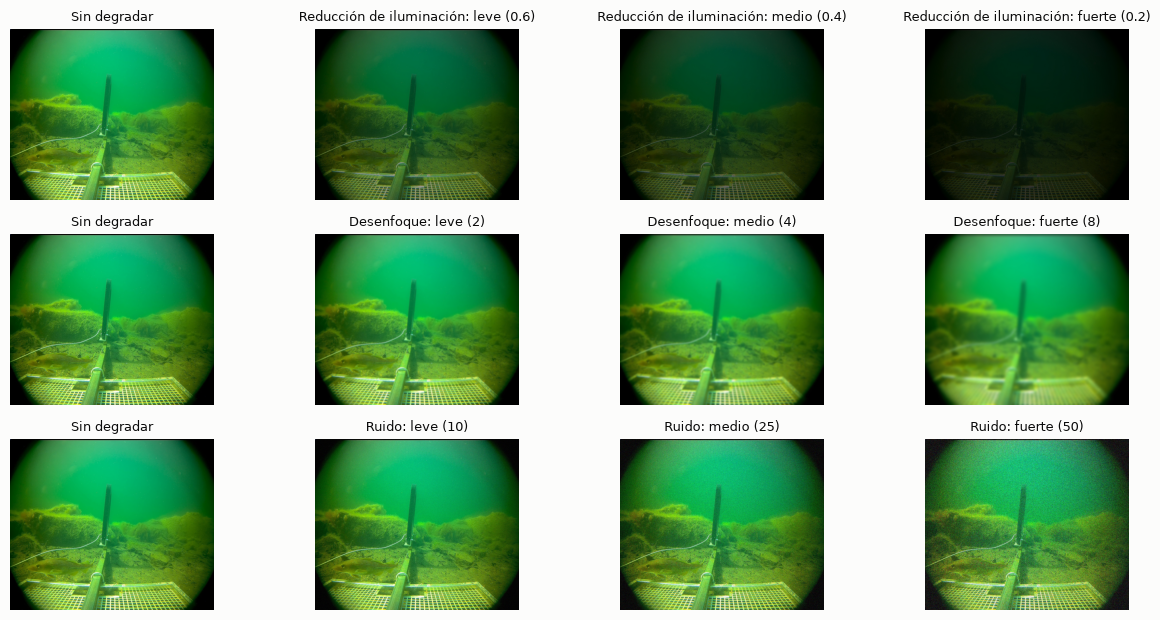

In [8]:
IDS_EJEMPLOS = random.Random(SEMILLA).sample(sorted(set(reales.id)), N_EJEMPLOS)
figura_condiciones(IDS_EJEMPLOS[0], "condiciones.png")

Recortar los valores a 0–255 y guardar en JPEG atenúan parte del ruido, así que el σ real de los archivos es menor que el declarado. Esta tabla muestra cuánto.

In [9]:
def sigma_real(id_img, nombre):
    """Desviación estándar de (imagen guardada − original) en una imagen, en niveles de 0 a 255."""
    original = cv2.imread(str(DIR_DATASET / "images" / "test" / f"{id_img}.jpg")).astype(np.float32)
    guardada = cv2.imread(str(DIR_CONJUNTOS / nombre / "images" / "test" / f"{id_img}.jpg")).astype(np.float32)
    return float((guardada - original).std())


ids_sigma = random.Random(SEMILLA).sample(ids, min(N_IMAGENES_SIGMA, len(ids)))
sigma_ruido = pd.DataFrame({nivel: {"σ declarado": valor, "σ real": np.mean([sigma_real(i, f"ruido_{valor}") for i in ids_sigma])}
                            for nivel, valor in zip(NIVELES, DEGRADACIONES["ruido"])}).T
sigma_ruido.round(2)

,σ declarado,σ real
Leve,10.0,7.34
Medio,25.0,17.05
Fuerte,50.0,31.91


## 4. Evaluación del mejor modelo (ítem 3.2)

Se evalúa cada condición con los mismos argumentos que `03` en test: 640 px, confianza ≥ 0,001, NMS multietiqueta con IoU 0,5 y detecciones exportadas con `save_json`. Las métricas salen del evaluador común.

In [10]:
modelo = YOLO(PESOS)


def evaluar_condicion(nombre):
    """Evalúa el modelo en una condición y devuelve sus detecciones en el formato común (px de la imagen)."""
    shutil.rmtree(DIR_EVALUACIONES / nombre, ignore_errors=True)   # sin detecciones, Ultralytics no escribe el archivo: no debe quedar uno anterior
    corrida = modelo.val(data=str(DIR_CONJUNTOS / nombre / "datos.yaml"), split="test", imgsz=LADO, batch=LOTE, conf=CONFIANZA_MINIMA, iou=IOU_NMS,
                         device=DISPOSITIVO, project=str(DIR_EVALUACIONES), name=nombre, exist_ok=True, plots=False, save_json=True)
    archivo = Path(corrida.save_dir) / "predictions.json"
    registros = json.loads(archivo.read_text(encoding="utf-8")) if archivo.exists() else []
    # Ultralytics guarda la caja como x, y (esquina superior izquierda), ancho y alto, y la clase sumándole 1
    filas = [(str(d["image_id"]), d["category_id"] - 1, d["score"], d["bbox"][0], d["bbox"][1],
              d["bbox"][0] + d["bbox"][2], d["bbox"][1] + d["bbox"][3]) for d in registros]
    return pd.DataFrame(filas, columns=["id", "clase_id", "confianza", "x1", "y1", "x2", "y2"])

Se evalúan todas las condiciones y se guardan sus detecciones. La celda imprime cuántas hay en cada una.

In [11]:
detecciones = {}
for nombre in CONDICIONES:
    detecciones[nombre] = evaluar_condicion(nombre)
    print(f"{nombre:18s} {len(detecciones[nombre]):7d} detecciones")

sin_degradar          3206 detecciones


iluminacion_0.6       3044 detecciones


iluminacion_0.4       2777 detecciones


iluminacion_0.2       2166 detecciones


desenfoque_2          2696 detecciones


desenfoque_4          1568 detecciones


desenfoque_8          1212 detecciones


ruido_10              2402 detecciones


ruido_25              1699 detecciones


ruido_50              1285 detecciones


Las mismas métricas de los otros cuadernos, con el evaluador y el umbral comunes.

In [12]:
ETIQUETAS = {"precision": "Precisión", "recall": "Recall", "F1": "F1", "mAP50": "mAP50", "mAP75": "mAP75", "mAP50_95": "mAP50-95"}


def evaluar(tabla_detecciones):
    """Métricas de un conjunto de detecciones con el evaluador y el umbral comunes."""
    return evaluar_detecciones(tabla_detecciones, reales, nombres=NOMBRES, umbral_confianza=UMBRAL_CONFIANZA)


metricas = {nombre: evaluar(d) for nombre, d in detecciones.items()}

Control: `sin_degradar` debe dar casi lo mismo que el test original, con las detecciones que guardó `03`. Si no, el proceso de guardar las imágenes estaría cambiando los resultados. En la ejecución completa, la celda se detiene si alguna diferencia supera 0,01.

In [13]:
originales = pd.read_csv(PREDICCIONES_TEST, dtype={"id": str}).query("id in @ids")
metricas_originales = evaluar(originales)
control = pd.DataFrame({"Test original": {e: metricas_originales[k] for k, e in ETIQUETAS.items()},
                        "Sin degradar": {e: metricas["sin_degradar"][k] for k, e in ETIQUETAS.items()}})
control["Diferencia"] = control["Sin degradar"] - control["Test original"]
assert PRUEBA_RAPIDA or control.Diferencia.abs().max() < 0.01, "Guardar de nuevo las imágenes cambia los resultados"
control.round(4)

,Test original,Sin degradar,Diferencia
Precisión,0.5528,0.5538,0.0010
Recall,0.4385,0.4411,0.0026
F1,0.4891,0.4911,0.0020
mAP50,0.4757,0.4746,-0.0011
mAP75,0.3799,0.3826,0.0027
mAP50-95,0.3420,0.3415,-0.0004


## 5. Resultados

Resultados por condición, en test. Las detecciones por imagen cuentan solo las que superan el umbral común.

La precisión se promedia entre clases, y una clase sin detecciones sobre el umbral aporta 0. Las columnas "Clases con detecciones" y "Precisión micro" (sin promediar por clase) permiten distinguirlo.

In [14]:
def etiqueta_condicion(nombre):
    """Texto corto para una condición en tablas y figuras."""
    c = CONDICIONES[nombre]
    return "Sin degradar" if c["tipo"] is None else f"{NOMBRES_TIPO[c['tipo']]}, {c['nivel'].lower()}"


tabla_condiciones = pd.DataFrame({etiqueta_condicion(n): {**{e: m[k] for k, e in ETIQUETAS.items()},
                                                         "Clases con detecciones": m["clases_con_detecciones"],
                                                         "Precisión micro": m["precision_micro"],
                                                         "Detecciones por imagen": (detecciones[n].confianza >= UMBRAL_CONFIANZA).sum() / len(ids)}
                                  for n, m in metricas.items()}).T.astype({"Clases con detecciones": int})
tabla_condiciones.round(3)

,Precisión,Recall,F1,mAP50,mAP75,mAP50-95,Clases con detecciones,Precisión micro,Detecciones por imagen
Sin degradar,0.554,0.441,0.491,0.475,0.383,0.342,22,0.761,1.837
"Reducción de iluminación, leve",0.524,0.424,0.469,0.466,0.356,0.322,22,0.728,1.854
"Reducción de iluminación, medio",0.510,0.398,0.447,0.472,0.323,0.305,21,0.711,1.781
"Reducción de iluminación, fuerte",0.427,0.242,0.309,0.314,0.195,0.182,18,0.695,1.362
"Desenfoque, leve",0.527,0.364,0.431,0.446,0.323,0.302,20,0.729,1.691
"Desenfoque, medio",0.341,0.159,0.217,0.286,0.160,0.184,17,0.632,1.020
"Desenfoque, fuerte",0.176,0.050,0.078,0.068,0.035,0.039,12,0.503,0.528
"Ruido, leve",0.428,0.276,0.336,0.365,0.241,0.239,19,0.742,1.468
"Ruido, medio",0.316,0.114,0.168,0.146,0.102,0.095,15,0.689,0.748
"Ruido, fuerte",0.181,0.030,0.052,0.051,0.044,0.035,11,0.506,0.256


Caída relativa respecto de `sin_degradar`, en porcentaje, de la condición que más degrada a la que menos, según el mAP50-95. Un valor de 100 % significa que la métrica llegó a cero.

In [15]:
METRICAS_CAIDA = list(ETIQUETAS.values())
caida = (100 * (1 - tabla_condiciones[METRICAS_CAIDA] / tabla_condiciones.loc["Sin degradar", METRICAS_CAIDA])).drop(index="Sin degradar").sort_values("mAP50-95", ascending=False)
caida.round(1)

,Precisión,Recall,F1,mAP50,mAP75,mAP50-95
"Ruido, fuerte",67.4,93.1,89.4,89.3,88.6,89.7
"Desenfoque, fuerte",68.2,88.6,84.0,85.7,90.8,88.6
"Ruido, medio",43.0,74.1,65.8,69.2,73.4,72.2
"Reducción de iluminación, fuerte",22.9,45.2,37.2,33.8,49.0,46.7
"Desenfoque, medio",38.4,64.0,55.9,39.8,58.3,46.1
"Ruido, leve",22.7,37.4,31.6,23.1,37.0,29.9
"Desenfoque, leve",4.8,17.5,12.3,6.0,15.5,11.7
"Reducción de iluminación, medio",7.9,9.7,8.9,0.5,15.6,10.6
"Reducción de iluminación, leve",5.4,3.9,4.6,1.8,7.0,5.7


Evolución de cada métrica según el nivel, una línea por tipo. Todas parten del mismo punto, `sin_degradar`.

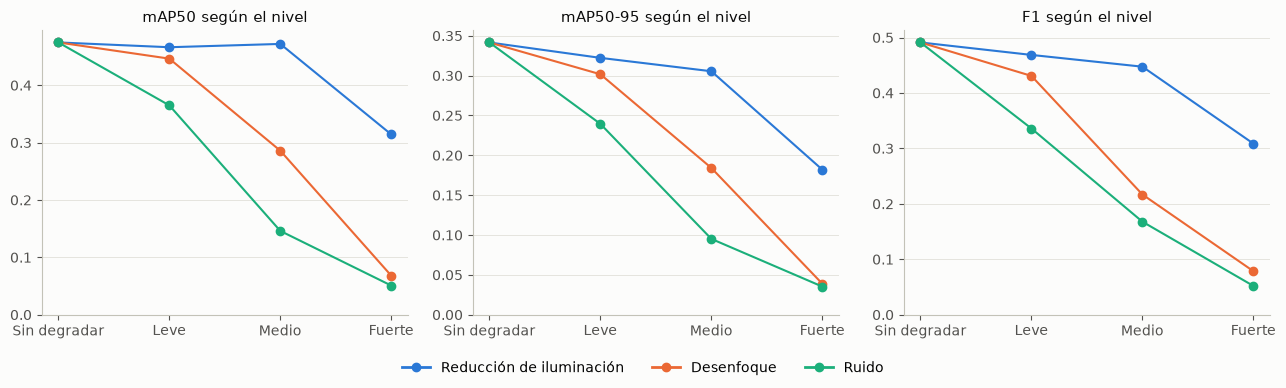

In [16]:
EJE_NIVELES = ["Sin degradar", *NIVELES]
fig, ejes = plt.subplots(1, 3, figsize=(13, 3.9), sharex=True)
for ax, clave in zip(ejes, ("mAP50", "mAP50_95", "F1")):
    for tipo, valores in DEGRADACIONES.items():
        serie = [metricas["sin_degradar"][clave], *[metricas[f"{tipo}_{v}"][clave] for v in valores]]
        ax.plot(EJE_NIVELES, serie, color=COLORES_TIPO[tipo], lw=1.5, marker="o", ms=6)
    ax.set(title=f"{ETIQUETAS[clave]} según el nivel", ylim=(0, None))
    ax.grid(axis="x", visible=False)
guardar(fig, "metricas_por_nivel.png", con_leyenda=True)

Caída del mAP50-95 en cada condición, ordenada de mayor a menor.

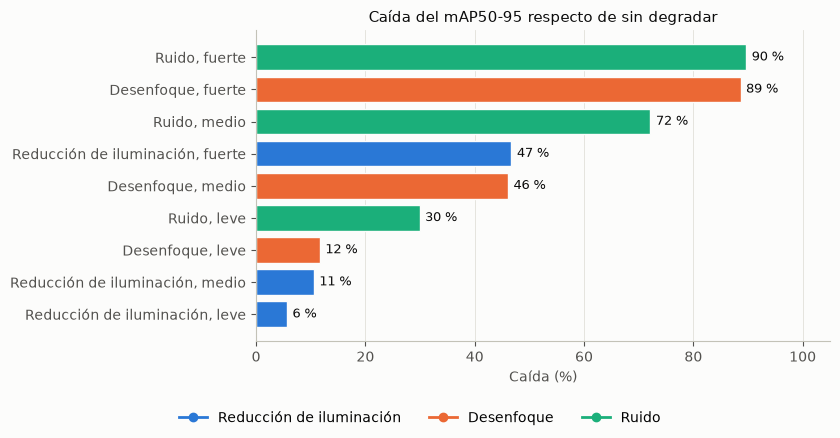

In [17]:
tipo_de_etiqueta = {etiqueta_condicion(n): c["tipo"] for n, c in CONDICIONES.items()}
ordenadas = caida["mAP50-95"].sort_values()
fig, ax = plt.subplots(figsize=(8.5, 4.4))
ax.barh(ordenadas.index, ordenadas, color=[COLORES_TIPO[tipo_de_etiqueta[e]] for e in ordenadas.index], edgecolor=FONDO, linewidth=1)
for y, valor in enumerate(ordenadas):
    ax.text(valor + 1, y, f"{valor:.0f} %", va="center", fontsize=9, color=TINTA)
ax.set(title="Caída del mAP50-95 respecto de sin degradar", xlabel="Caída (%)", xlim=(0, max(105, ordenadas.max() + 8)))
ax.grid(axis="y", visible=False)
guardar(fig, "caida_mAP50_95.png", con_leyenda=True)

AP50 por clase en cada condición, de la clase con más instancias a la que tiene menos (entre paréntesis).

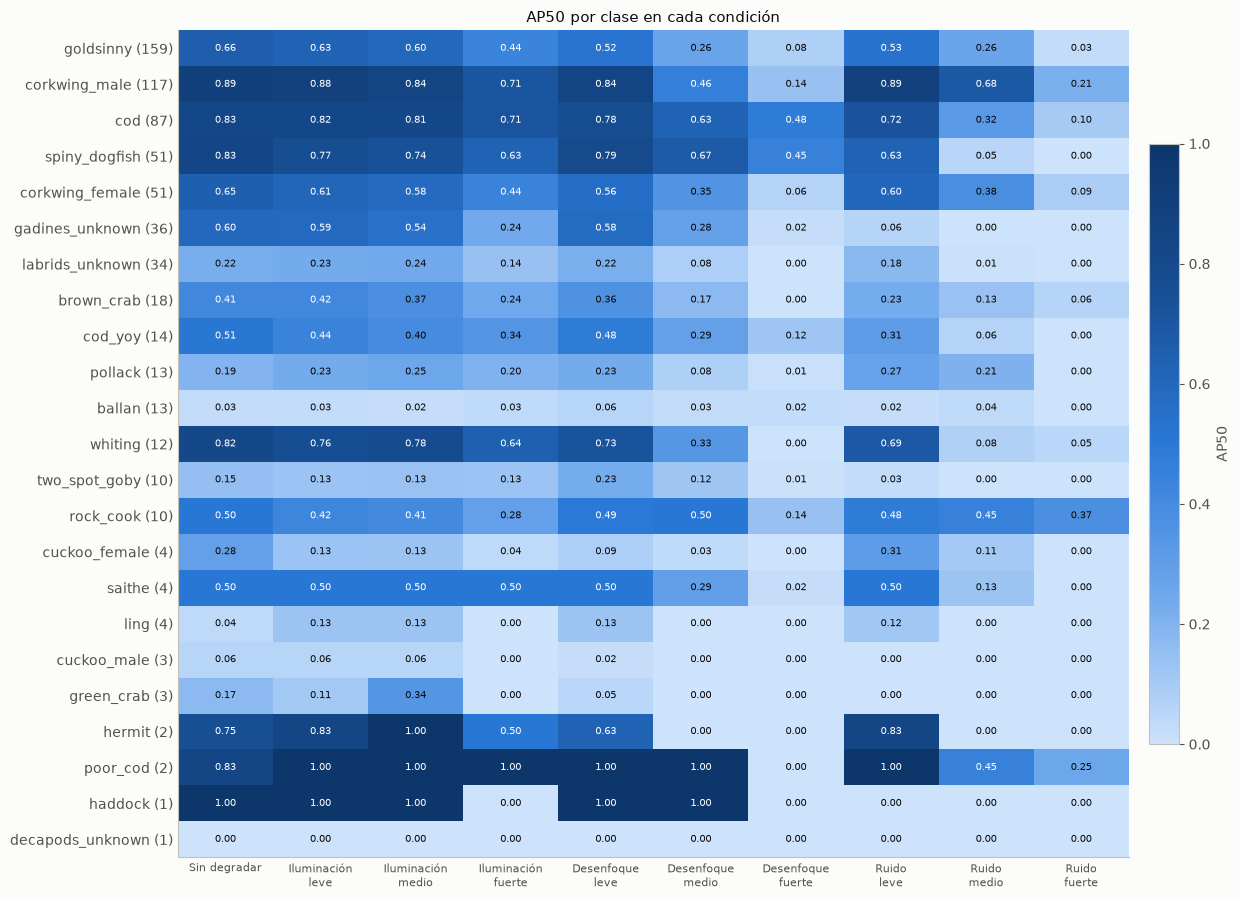

In [18]:
orden = metricas["sin_degradar"]["por_clase"].sort_values("instancias", ascending=False)
ap_por_clase = pd.DataFrame({etiqueta_condicion(n): m["por_clase"].set_index("clase").AP50 for n, m in metricas.items()}).loc[orden.clase]
ap_por_clase.index = [f"{c} ({n})" for c, n in zip(orden.clase, orden.instancias)]

fig, ax = plt.subplots(figsize=(3 + 0.95 * ap_por_clase.shape[1], 0.3 * len(ap_por_clase) + 2.2))
imagen = ax.imshow(ap_por_clase.to_numpy(), cmap=MAPA_AP, vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(ap_por_clase.shape[1]), [e.replace(", ", "\n").replace("Reducción de iluminación", "Iluminación") for e in ap_por_clase.columns], fontsize=8)
ax.set_yticks(range(len(ap_por_clase)), ap_por_clase.index)
ax.tick_params(length=0)
ax.grid(False)
for (i, j), valor in np.ndenumerate(ap_por_clase.to_numpy()):
    ax.text(j, i, f"{valor:.2f}", ha="center", va="center", fontsize=7, color="white" if valor >= 0.4 else TINTA)
ax.set_title("AP50 por clase en cada condición")
fig.colorbar(imagen, ax=ax, label="AP50", fraction=0.03, pad=0.02)
guardar(fig, "ap50_por_clase.png")

Tamaño de cada caja real: su lado mayor en la entrada de 640 px, agrupado según `LIMITES_TAMANO`.

In [19]:
escala = {i: LADO / max(Image.open(DIR_DATASET / "images" / "test" / f"{i}.jpg").size) for i in ids}
lado_mayor = np.maximum(reales.x2 - reales.x1, reales.y2 - reales.y1) * reales.id.map(escala)
tamanos = pd.cut(lado_mayor, LIMITES_TAMANO, labels=ETIQUETAS_TAMANO, right=False)
print("Cajas reales por tamaño:", tamanos.value_counts(sort=False).to_dict())

Cajas reales por tamaño: {'Menos de 32 px': 148, '32 a 64 px': 206, '64 a 128 px': 171, '128 px o más': 124}


Fracción de cajas reales que tienen alguna detección de su clase con IoU ≥ 0,5 y confianza sobre el umbral común, según el tamaño del objeto.

In [20]:
def encontradas_por_tamano(nombre):
    """Fracción de cajas reales encontradas en una condición, por tamaño del objeto."""
    grupos = dict(tuple(detecciones[nombre].query("confianza >= @UMBRAL_CONFIANZA").groupby("id")))
    encontradas = []
    for caja in reales.itertuples():
        candidatas = grupos.get(caja.id)
        misma_clase = candidatas[candidatas.clase_id == caja.clase_id] if candidatas is not None else []
        encontrada = len(misma_clase) > 0 and iou(np.array([[caja.x1, caja.y1, caja.x2, caja.y2]], dtype=float),
                                                  misma_clase[COLUMNAS_CAJA].to_numpy(dtype=float)).max() >= IOU_ENCONTRADA
        encontradas.append(encontrada)
    return pd.Series(encontradas, index=reales.index, dtype=float).groupby(tamanos, observed=False).mean()


por_tamano = pd.DataFrame({etiqueta_condicion(n): encontradas_por_tamano(n) for n in CONDICIONES}).T
por_tamano.round(3)

,Menos de 32 px,32 a 64 px,64 a 128 px,128 px o más
Sin degradar,0.392,0.636,0.778,0.806
"Reducción de iluminación, leve",0.351,0.607,0.760,0.806
"Reducción de iluminación, medio",0.338,0.549,0.725,0.766
"Reducción de iluminación, fuerte",0.182,0.383,0.556,0.694
"Desenfoque, leve",0.338,0.539,0.655,0.798
"Desenfoque, medio",0.068,0.233,0.339,0.637
"Desenfoque, fuerte",0.000,0.087,0.105,0.363
"Ruido, leve",0.196,0.481,0.632,0.742
"Ruido, medio",0.047,0.180,0.363,0.395
"Ruido, fuerte",0.000,0.029,0.094,0.137


Detecciones del modelo sobre las mismas imágenes en cada condición, con el umbral común.

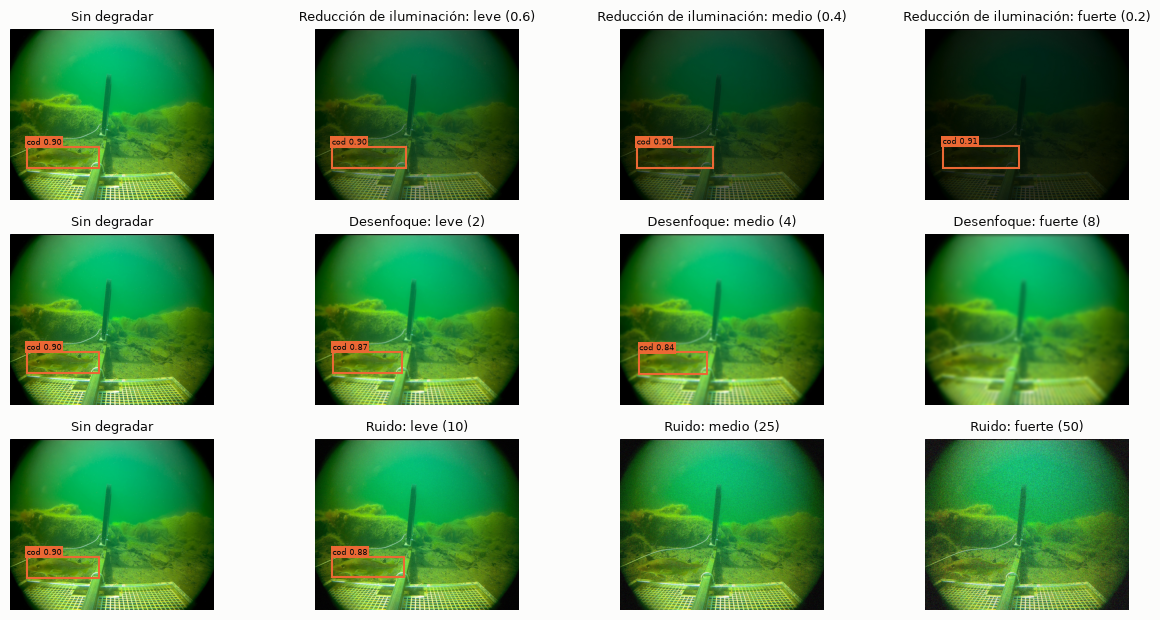

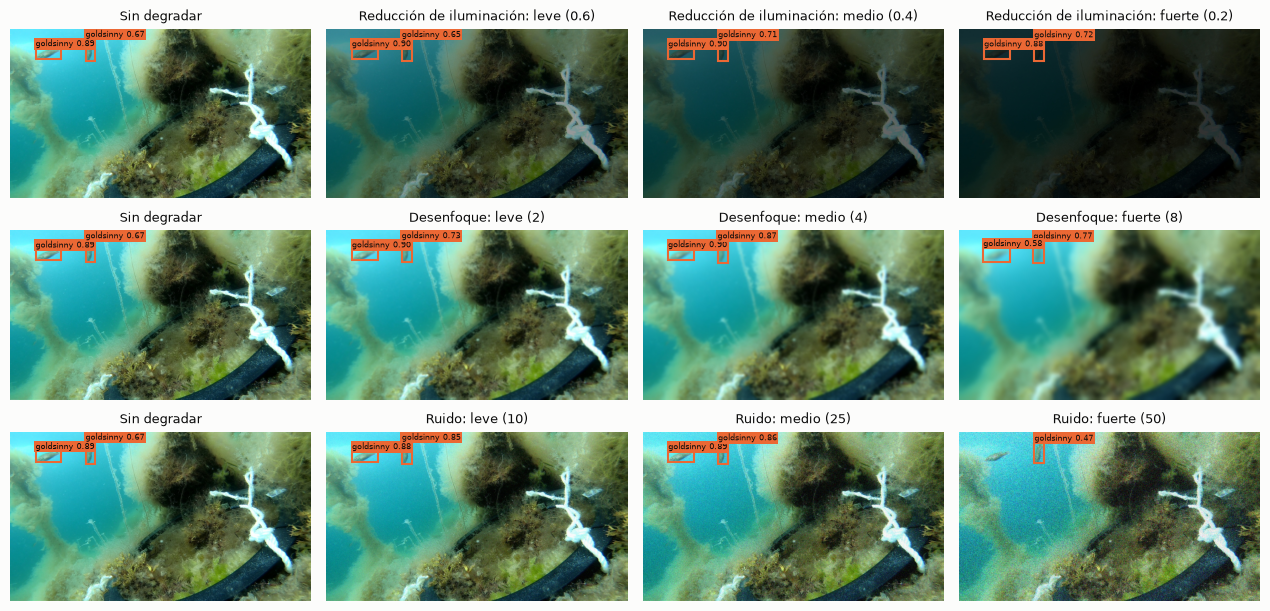

In [21]:
for n, id_img in enumerate(IDS_EJEMPLOS, start=1):
    figura_condiciones(id_img, f"detecciones_ejemplo_{n}.png", detecciones)

## 6. ✍️ Análisis (ítem 3.3; completar por el grupo)

- **Elección de los tipos y niveles de degradación**:
- **Cómo afecta cada condición al detector**:
- **Qué condiciones producen la mayor degradación y por qué**:

## 7. Exportación

Guarda las tablas sin redondear y las detecciones de cada condición, junto a las figuras. Con estas detecciones se pueden recalcular las métricas sin usar la GPU.

In [22]:
tablas = {"metricas_por_condicion.csv": tabla_condiciones, "caida_relativa.csv": caida, "ap50_por_clase.csv": ap_por_clase,
          "encontradas_por_tamano.csv": por_tamano, "ruido_sigma_real.csv": sigma_ruido}
for nombre, t in tablas.items():
    t.to_csv(DIR_RESULTADOS / nombre)
DIR_PREDICCIONES = DIR_RESULTADOS / "predicciones"
DIR_PREDICCIONES.mkdir(exist_ok=True)
for anterior in DIR_PREDICCIONES.glob("*.csv"):       # si cambian los niveles, no deben quedar archivos de condiciones anteriores
    anterior.unlink()
for nombre, d in detecciones.items():
    d.to_csv(DIR_PREDICCIONES / f"{nombre}.csv", index=False)
print(f"Archivos en {DIR_RESULTADOS.relative_to(RAIZ)}:", *sorted(p.name for p in DIR_RESULTADOS.iterdir()), sep="\n  ")

Archivos en resultados\robustez:
  ap50_por_clase.csv
  ap50_por_clase.png
  caida_mAP50_95.png
  caida_relativa.csv
  condiciones.png
  detecciones_ejemplo_1.png
  detecciones_ejemplo_2.png
  encontradas_por_tamano.csv
  metricas_por_condicion.csv
  metricas_por_nivel.png
  predicciones
  ruido_sigma_real.csv


## ✍️ Declaración de uso de IA generativa

> Completar según lo que pide la tarea (herramienta y propósito específico).